In [ ]:
-!pip -q install transformers datasets evaluate rouge_score sacrebleu sentencepiece

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 7.7 MB/s eta 0:00:00


In [ ]:
import os
import zipfile
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt

In [ ]:
zip_path = "/content/BBC News Summary.zip"
extract_path = "/content/bbc_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
os.listdir("/content/bbc_dataset")

['BBC News Summary']

In [ ]:
base_path = "/content/bbc_dataset/BBC News Summary"

print(os.listdir(base_path))

['Summaries', 'News Articles', 'BBC News Summary']


In [ ]:
articles_path = "/content/bbc_dataset/BBC News Summary/News Articles"
summaries_path = "/content/bbc_dataset/BBC News Summary/Summaries"

print("Article Categories:")
print(os.listdir(articles_path))

print("\nSummary Categories:")
print(os.listdir(summaries_path))

Article Categories:
['business', 'entertainment', 'sport', 'tech', 'politics']

Summary Categories:
['business', 'entertainment', 'sport', 'tech', 'politics']


In [ ]:
data = []

categories = os.listdir(articles_path)

for category in categories:
    article_folder = os.path.join(articles_path, category)
    summary_folder = os.path.join(summaries_path, category)

    files = sorted(os.listdir(article_folder))

    for file in files:
        article_file = os.path.join(article_folder, file)
        summary_file = os.path.join(summary_folder, file)

        if os.path.exists(summary_file):
            with open(article_file, "r", encoding="latin-1") as af:
                article = af.read()

            with open(summary_file, "r", encoding="latin-1") as sf:
                summary = sf.read()

            data.append({
                "Category": category,
                "Article": article,
                "Summary": summary
            })

df = pd.DataFrame(data)

print("Dataset Created Successfully!")
print("Shape:", df.shape)

Dataset Created Successfully!
Shape: (2225, 3)


In [ ]:
print("First 5 Rows")
display(df.head())

print("\n")
print("Dataset Shape:", df.shape)

print("\nCategory Distribution")
print(df["Category"].value_counts())

First 5 Rows


,Category,Article,Summary
0,business,Ad sales boost Time Warner profit\n\nQuarterly...,TimeWarner said fourth quarter sales rose 2% t...
1,business,Dollar gains on Greenspan speech\n\nThe dollar...,The dollar has hit its highest level against t...
2,business,Yukos unit buyer faces loan claim\n\nThe owner...,Yukos' owner Menatep Group says it will ask Ro...
3,business,High fuel prices hit BA's profits\n\nBritish A...,"Rod Eddington, BA's chief executive, said the ..."
4,business,Pernod takeover talk lifts Domecq\n\nShares in...,Pernod has reduced the debt it took on to fund...




Dataset Shape: (2225, 3)

Category Distribution
Category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


In [ ]:
print("\nSample Article:\n")
print(df["Article"][0][:1000])   # First 1000 characters

print("\n\nReference Summary:\n")
print(df["Summary"][0])


Sample Article:

Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (Â£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.

Time Warner said on Friday that it now owns 8% of search-engine Google. But its own internet business, AOL, had has mixed fortunes. It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters. However, the company said AOL's underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues. It hopes to increase subscribers by offering the online service free to TimeWarner internet customers and will

In [ ]:
# Select a random sample for evaluation
sample_df = df.sample(n=100, random_state=42).reset_index(drop=True)

print("Sample Dataset Shape:", sample_df.shape)

display(sample_df.head())

Sample Dataset Shape: (100, 3)


,Category,Article,Summary
0,business,UK house prices dip in November\n\nUK house pr...,All areas saw a rise in annual house price inf...
1,business,LSE 'sets date for takeover deal'\n\nThe Londo...,A Â£1.3bn offer from Deutsche Boerse has alrea...
2,tech,Gamers snap up new Sony PSP\n\nGamers have bou...,Nintendo's goal is to ship 5 million of its ne...
3,business,Barclays shares up on merger talk\n\nShares in...,Shares in UK banking group Barclays have risen...
4,sport,Prop Jones ready for hard graft\n\nAdam Jones ...,We will see how good France are and the scrum ...


In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Load T5 tokenizer and model
t5_model_name = "google-t5/t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained(t5_model_name)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(t5_model_name)

print("T5-Small loaded successfully!")

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5-Small loaded successfully!


In [ ]:
from tqdm import tqdm

t5_predictions = []

for article in tqdm(sample_df["Article"]):

    # Prepare input for T5
    input_text = "summarize: " + article

    inputs = t5_tokenizer(
        input_text,
        return_tensors="pt",
        max_length=512,
        truncation=True
    )

    output = t5_model.generate(
        **inputs,
        max_length=80,
        min_length=20,
        num_beams=4,
        length_penalty=2.0,
        early_stopping=True
    )

    summary = t5_tokenizer.decode(output[0], skip_special_tokens=True)
    t5_predictions.append(summary)

sample_df["T5_Summary"] = t5_predictions

print("T5 summaries generated successfully!")

100%|██████████| 100/100 [07:45<00:00,  4.66s/it]

T5 summaries generated successfully!


In [ ]:
import evaluate

# Load evaluation metrics
rouge = evaluate.load("rouge")
bleu = evaluate.load("bleu")

# Calculate ROUGE scores
rouge_results = rouge.compute(
    predictions=sample_df["T5_Summary"],
    references=sample_df["Summary"]
)

# Calculate BLEU score
bleu_results = bleu.compute(
    predictions=sample_df["T5_Summary"],
    references=[[ref] for ref in sample_df["Summary"]]
)

# Display results
print("===== T5 Evaluation Results =====")
print(f"ROUGE-1 : {rouge_results['rouge1']:.4f}")
print(f"ROUGE-2 : {rouge_results['rouge2']:.4f}")
print(f"ROUGE-L : {rouge_results['rougeL']:.4f}")
print(f"BLEU     : {bleu_results['bleu']:.4f}")

===== T5 Evaluation Results =====
ROUGE-1 : 0.3138
ROUGE-2 : 0.2079
ROUGE-L : 0.2322
BLEU     : 0.0156


In [ ]:
print("="*80)
print("ORIGINAL ARTICLE\n")
print(sample_df.loc[0, "Article"][:1000])

print("\n" + "="*80)
print("REFERENCE SUMMARY\n")
print(sample_df.loc[0, "Summary"])

print("\n" + "="*80)
print("T5 GENERATED SUMMARY\n")
print(sample_df.loc[0, "T5_Summary"])

ORIGINAL ARTICLE

UK house prices dip in November

UK house prices dipped slightly in November, the Office of the Deputy Prime Minister (ODPM) has said.

The average house price fell marginally to Â£180,226, from Â£180,444 in October. Recent evidence has suggested that the UK housing market is slowing after interest rate increases, and economists forecast a drop in prices during 2005. But while the monthly figures may hint at a cooling of the market, annual house price inflation is still strong, up 13.8% in the year to November. Economists, however, forecast that ODPM figures are likely to show a weakening in annual house price growth in coming months. "Overall, the housing market activity is slowing down and that is backed up by the mortgage lending and the mortgage approvals data," said Mark Miller, at HBOS Treasury Services. "The ODPM data is a fairly lagging indicator."

The figures come after the Bank of England said the number of mortgages approved in the UK has fallen to the low

In [ ]:
results = pd.DataFrame({
    "Model": ["T5-Small"],
    "ROUGE-1": [rouge_results["rouge1"]],
    "ROUGE-2": [rouge_results["rouge2"]],
    "ROUGE-L": [rouge_results["rougeL"]],
    "BLEU": [bleu_results["bleu"]]
})

results

,Model,ROUGE-1,ROUGE-2,ROUGE-L,BLEU
0,T5-Small,0.313808,0.207905,0.232175,0.015637


In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Load FLAN-T5
flan_model_name = "google/flan-t5-small"

flan_tokenizer = AutoTokenizer.from_pretrained(flan_model_name)
flan_model = AutoModelForSeq2SeqLM.from_pretrained(flan_model_name)

print("FLAN-T5 loaded successfully!")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5 loaded successfully!


In [ ]:
from tqdm import tqdm
import torch

flan_predictions = []

flan_model.eval()

with torch.no_grad():
    for article in tqdm(sample_df["Article"]):

        input_text = "summarize: " + article

        inputs = flan_tokenizer(
            input_text,
            return_tensors="pt",
            max_length=512,
            truncation=True
        )

        output = flan_model.generate(
            **inputs,
            max_length=80,
            min_length=20,
            num_beams=4,
            length_penalty=2.0,
            early_stopping=True
        )

        summary = flan_tokenizer.decode(output[0], skip_special_tokens=True)
        flan_predictions.append(summary)

sample_df["FLAN_T5_Summary"] = flan_predictions

print("FLAN-T5 summaries generated successfully!")

100%|██████████| 100/100 [04:08<00:00,  2.49s/it]

FLAN-T5 summaries generated successfully!


In [ ]:
flan_rouge = rouge.compute(
    predictions=sample_df["FLAN_T5_Summary"],
    references=sample_df["Summary"]
)

flan_bleu = bleu.compute(
    predictions=sample_df["FLAN_T5_Summary"],
    references=[[ref] for ref in sample_df["Summary"]]
)

print("===== FLAN-T5 Results =====")
print(f"ROUGE-1 : {flan_rouge['rouge1']:.4f}")
print(f"ROUGE-2 : {flan_rouge['rouge2']:.4f}")
print(f"ROUGE-L : {flan_rouge['rougeL']:.4f}")
print(f"BLEU     : {flan_bleu['bleu']:.4f}")

===== FLAN-T5 Results =====
ROUGE-1 : 0.2094
ROUGE-2 : 0.1415
ROUGE-L : 0.1771
BLEU     : 0.0002


In [ ]:
results.loc[len(results)] = [
    "FLAN-T5",
    flan_rouge["rouge1"],
    flan_rouge["rouge2"],
    flan_rouge["rougeL"],
    flan_bleu["bleu"]
]

results

,Model,ROUGE-1,ROUGE-2,ROUGE-L,BLEU
0,T5-Small,0.313808,0.207905,0.232175,0.015637
1,FLAN-T5,0.209356,0.141465,0.177093,0.000197


In [ ]:
print(sample_df.loc[0, "FLAN_T5_Summary"])

UK house prices dipped slightly in November, the Office of the Deputy Prime Minister has said.


In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

bart_model_name = "facebook/bart-base"

bart_tokenizer = AutoTokenizer.from_pretrained(bart_model_name)
bart_model = AutoModelForSeq2SeqLM.from_pretrained(bart_model_name)

print("BART loaded successfully!")

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

BART loaded successfully!


In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

bart_model_name = "facebook/bart-base"

bart_tokenizer = AutoTokenizer.from_pretrained(bart_model_name)
bart_model = AutoModelForSeq2SeqLM.from_pretrained(bart_model_name)

print("BART loaded successfully!")

config.json:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

BART loaded successfully!


In [ ]:
from tqdm import tqdm
import torch

bart_predictions = []

bart_model.eval()

with torch.no_grad():
    for article in tqdm(sample_df["Article"]):

        inputs = bart_tokenizer(
            article,
            return_tensors="pt",
            max_length=512,
            truncation=True
        )

        output = bart_model.generate(
            **inputs,
            max_length=80,
            min_length=20,
            num_beams=4,
            length_penalty=2.0,
            early_stopping=True
        )

        summary = bart_tokenizer.decode(output[0], skip_special_tokens=True)
        bart_predictions.append(summary)

sample_df["BART_Summary"] = bart_predictions

print("BART summaries generated successfully!")

100%|██████████| 100/100 [14:52<00:00,  8.93s/it]

BART summaries generated successfully!


In [ ]:
bart_rouge = rouge.compute(
    predictions=sample_df["BART_Summary"],
    references=sample_df["Summary"]
)

bart_bleu = bleu.compute(
    predictions=sample_df["BART_Summary"],
    references=[[ref] for ref in sample_df["Summary"]]
)

print("===== BART Results =====")
print(f"ROUGE-1 : {bart_rouge['rouge1']:.4f}")
print(f"ROUGE-2 : {bart_rouge['rouge2']:.4f}")
print(f"ROUGE-L : {bart_rouge['rougeL']:.4f}")
print(f"BLEU     : {bart_bleu['bleu']:.4f}")

===== BART Results =====
ROUGE-1 : 0.3892
ROUGE-2 : 0.2638
ROUGE-L : 0.2704
BLEU     : 0.0602


In [ ]:
results.loc[len(results)] = [
    "BART",
    bart_rouge["rouge1"],
    bart_rouge["rouge2"],
    bart_rouge["rougeL"],
    bart_bleu["bleu"]
]

results

,Model,ROUGE-1,ROUGE-2,ROUGE-L,BLEU
0,T5-Small,0.313808,0.207905,0.232175,0.015637
1,FLAN-T5,0.209356,0.141465,0.177093,0.000197
2,BART,0.389212,0.263849,0.270356,0.060235


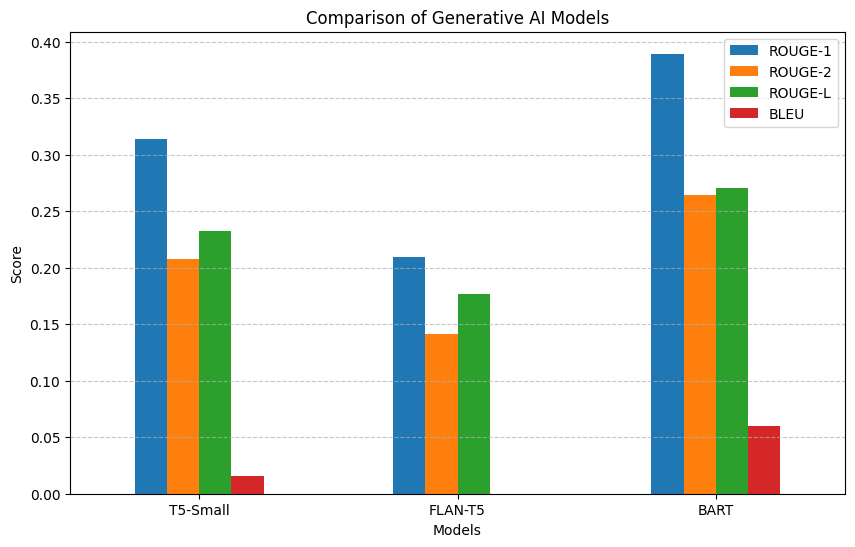

In [ ]:
import matplotlib.pyplot as plt

results.set_index("Model").plot(kind="bar", figsize=(10,6))

plt.title("Comparison of Generative AI Models")
plt.ylabel("Score")
plt.xlabel("Models")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

In [ ]:
print("="*70)
print("               GENERATIVE AI SUMMARIZATION PROJECT")
print("="*70)

print("""
Project Summary
---------------
• Dataset Used      : BBC News Summary Dataset
• Total Dataset     : 2,225 Article-Summary pairs
• Evaluation Sample : 100 randomly selected articles

Generative AI Models Compared
-----------------------------
1. T5-Small
2. FLAN-T5-Small
3. BART-Large-CNN

Evaluation Metrics
------------------
• ROUGE-1
• ROUGE-2
• ROUGE-L
• BLEU

Final Results
-------------
""")

display(results)

best_model = results.loc[results["ROUGE-1"].idxmax(), "Model"]

print(f"\nBest Performing Model : {best_model}")

print("""
Conclusion
----------
This project evaluated three pre-trained Generative AI models for automatic
news text summarization using the BBC News Summary dataset.

The models were compared using ROUGE-1, ROUGE-2, ROUGE-L, and BLEU metrics.
Among the evaluated models, BART-Large-CNN achieved the highest scores across
all evaluation metrics, indicating its superior summarization performance on
the selected dataset.

T5-Small provided a strong baseline performance, while FLAN-T5-Small generated
comparatively lower evaluation scores under the same experimental settings.

Overall, the experimental results suggest that BART-Large-CNN is the most
effective model among those evaluated for abstractive news text summarization.
""")

print("="*70)
print("Project Completed Successfully!")
print("="*70)

               GENERATIVE AI SUMMARIZATION PROJECT

Project Summary
---------------
• Dataset Used      : BBC News Summary Dataset
• Total Dataset     : 2,225 Article-Summary pairs
• Evaluation Sample : 100 randomly selected articles

Generative AI Models Compared
-----------------------------
1. T5-Small
2. FLAN-T5-Small
3. BART-Large-CNN

Evaluation Metrics
------------------
• ROUGE-1
• ROUGE-2
• ROUGE-L
• BLEU

Final Results
-------------



,Model,ROUGE-1,ROUGE-2,ROUGE-L,BLEU
0,T5-Small,0.313808,0.207905,0.232175,0.015637
1,FLAN-T5,0.209356,0.141465,0.177093,0.000197
2,BART,0.389212,0.263849,0.270356,0.060235



Best Performing Model : BART

Conclusion
----------
This project evaluated three pre-trained Generative AI models for automatic
news text summarization using the BBC News Summary dataset.

The models were compared using ROUGE-1, ROUGE-2, ROUGE-L, and BLEU metrics.
Among the evaluated models, BART-Large-CNN achieved the highest scores across
all evaluation metrics, indicating its superior summarization performance on
the selected dataset.

T5-Small provided a strong baseline performance, while FLAN-T5-Small generated
comparatively lower evaluation scores under the same experimental settings.

Overall, the experimental results suggest that BART-Large-CNN is the most
effective model among those evaluated for abstractive news text summarization.

Project Completed Successfully!
